**Integrantes**: *Marco Antonio Aragon Vivas, Juan David Reyes Burbano, Maria Paula Pinillo Olave, María José Suárez Toro, Laura Daniela Astudillo Ortega.*

# Proyecto 2. Sistema de detección, segmentación y clasificación de fracturas pélvicas mediante tomografía computarizada

**Sistema PENGWIN 2.5D multitarea**
> Uso académico: el modelo no ha sido validado clínicamente y no debe utilizarse para tomar decisiones quirúrgicas reales.

Las fracturas pélvicas pueden generar varios fragmentos óseos, por lo que identificarlos y medir su separación es una tarea importante para el análisis de estas lesiones. En este proyecto trabajamos con el dataset PENGWIN Task 1 (CT), presentado en el challenge MICCAI 2024, para desarrollar un sistema que permita analizar tomografías computarizadas de la pelvis.

El objetivo es detectar las regiones óseas (sacro, coxal izquierdo y coxal derecho), segmentar los fragmentos de cada región, clasificarlos según el hueso al que pertenecen y calcular la distancia entre los fragmentos secundarios y el fragmento principal en milímetros.

Para esto desarrollamos un modelo multitarea con una entrada 2.5D, que utiliza varios cortes de la tomografía para incorporar información de los cortes vecinos. Los resultados se integran en una aplicación web que permite visualizar las predicciones por corte y la reconstrucción tridimensional de los fragmentos.

---

## 0. Preparación

En esta sección importamos las librerías que vamos a utilizar durante el proyecto y definimos las rutas de las imágenes, las etiquetas y el caché. También establecemos los nombres y colores de las tres regiones óseas: sacro, coxal izquierdo y coxal derecho. Estos colores se mantienen en las visualizaciones del notebook y en la aplicación.

Antes de continuar, comprobamos que las imágenes y sus etiquetas estén disponibles y que ambos conjuntos contengan los mismos casos. La verificación encontró **100 casos con imagen y etiqueta**, por lo que podemos continuar con la preparación de los datos.

In [ ]:
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
from matplotlib.patches import Rectangle
from scipy import ndimage

RAIZ = Path.cwd()
IMAGES = RAIZ / "data" / "raw" / "images"
LABELS = RAIZ / "data" / "raw" / "labels"
CACHE = RAIZ / "data" / "cache"

HUESO = {1: "sacro", 2: "coxal izquierdo", 3: "coxal derecho"}
COLOR = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
FRAG = {1: "n_frag_sa", 2: "n_frag_lh", 3: "n_frag_rh"}
NEUTRO, GRIS, TINTA = "#52514e", "#c3c2b7", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

casos = sorted(p.stem for p in IMAGES.glob("*.mha"))
assert casos and casos == sorted(p.stem for p in LABELS.glob("*.mha")), "Faltan datos: ver data/README.md"
print(f"{len(casos)} casos con imagen y etiqueta en {IMAGES.parent}")

100 casos con imagen y etiqueta en C:\Users\usuario\Desktop\Analitica carlos\proyecto\entregas\entrega final\data\raw


---

# Capítulo 1 · Exploración y preparación de los datos

Antes de diseñar ningún modelo hay que saber qué hay en los datos y convertirlos en algo que una red pueda leer: 31 GB de volúmenes en formatos, escalas y orientaciones distintos tienen que acabar en cortes 256×256, todos en la misma escala física y la misma orientación, que se lean al azar en milisegundos. El capítulo lo hace en cuatro pasos:

1. **Explorar los archivos y sus características** (1.1–1.7): qué trae cada archivo, qué significa su etiqueta y qué problemas esconde (ejes invertidos, escalas distintas, pacientes girados, cortes sin pelvis). Cada problema termina en una regla para el preprocesado.
2. **Construir el caché** (1.8–1.11): el preprocesado vive en `build_cache.py`; aquí se prueba sobre una muestra con las funciones del propio script y se verifica sobre los 100 casos.
3. **Definir la entrada del modelo** (1.12): tres ventanas de Hounsfield por corte y una pila de cortes vecinos.
4. **Analizar los datos y establecer las decisiones de diseño** (1.13–1.14): ocho análisis, cada uno con la decisión que justifica, y la partición por paciente.

## 1.1. Revisión de los archivos y sus cabeceras

Antes de procesar las tomografías, revisamos las cabeceras de las imágenes y sus máscaras para conocer sus dimensiones, el espaciado de los vóxeles y la orientación. Esta información es necesaria para comprobar que ambas estén alineadas y para calcular distancias en milímetros más adelante.

Para hacerlo, leemos las cabeceras sin cargar los vóxeles completos, lo que permite revisar los 100 casos de forma rápida.

In [ ]:
def cabecera(ruta: Path) -> dict:
    r = sitk.ImageFileReader()
    r.SetFileName(str(ruta))
    r.ReadImageInformation()
    return {
        **dict(zip(("nz", "ny", "nx"), r.GetSize()[::-1])),
        **dict(zip(("sz", "sy", "sx"), r.GetSpacing()[::-1])),
        "direccion": tuple(int(round(v)) for v in r.GetDirection()),
        "tipo": sitk.GetPixelIDValueAsString(r.GetPixelID()),
    }

def gb(carpeta: Path) -> float:
    return sum(p.stat().st_size for p in carpeta.glob("*.mha")) / 1024**3

t0 = time.perf_counter()
cab = pd.DataFrame.from_dict({c: cabecera(IMAGES / f"{c}.mha") for c in casos}, orient="index")
cab_lab = pd.DataFrame.from_dict({c: cabecera(LABELS / f"{c}.mha") for c in casos}, orient="index")
cab.index.name = "case_id"
t_cab = time.perf_counter() - t0

geometria = ["nz", "ny", "nx", "sz", "sy", "sx"]
misma = (np.isclose(cab[geometria].to_numpy(float), cab_lab[geometria].to_numpy(float), atol=1e-4).all(axis=1)
         & (cab.direccion == cab_lab.direccion).to_numpy())

print(f"{2 * len(casos)} cabeceras leídas en {t_cab:.2f} s, sin cargar un solo vóxel")
print(f"Imagen y etiqueta con la misma geometría: {misma.sum()} de {len(casos)} casos")
print(f"Tipo de dato en disco: imágenes {', '.join(cab.tipo.unique())} · etiquetas {', '.join(cab_lab.tipo.unique())}")
print(f"Tamaño en disco: imágenes {gb(IMAGES):.1f} GB · etiquetas {gb(LABELS):.1f} GB")
cab.drop(columns="tipo").head()

200 cabeceras leídas en 0.68 s, sin cargar un solo vóxel
Imagen y etiqueta con la misma geometría: 100 de 100 casos
Tipo de dato en disco: imágenes 32-bit signed integer, 16-bit signed integer · etiquetas 16-bit signed integer, 8-bit unsigned integer
Tamaño en disco: imágenes 18.8 GB · etiquetas 12.6 GB


,nz,ny,nx,sz,sy,sx,direccion
case_id,,,,,,,
001,401,512,512,0.8,0.781250,0.781250,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"
002,337,276,413,0.8,0.824219,0.824219,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
003,285,381,512,1.0,0.759766,0.759766,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
004,224,254,386,1.0,0.843750,0.843750,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
005,312,512,512,1.0,0.896484,0.896484,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"


Los resultados muestran que los 100 casos tienen la misma geometría entre la imagen y su máscara. Sin embargo, las dimensiones, el espaciado y la orientación varían entre pacientes, por lo que será necesario tenerlos en cuenta durante el preprocesamiento. También observamos que las imágenes y las etiquetas utilizan distintos tipos de dato y ocupan aproximadamente 18,8 GB y 12,6 GB, respectivamente.

Los archivos están en formato `.mha` (MetaImage), aunque el enunciado menciona NIfTI. Esto no impide obtener el espaciado físico desde la cabecera, que es el dato necesario para las mediciones. Además, la comprobación realizada en esta sección se limita a las dimensiones, el espaciado y la dirección; el código de lectura de cada caso vuelve a verificar la geometría, incluido el origen.

## 1.2. Revisión de un caso

Para entender cómo están almacenadas las imágenes y sus etiquetas, cargamos el caso `001` y revisamos sus dimensiones, tipos de dato y valores de la máscara. También convertimos la imagen a `int16` y la etiqueta a `uint8` para reducir el espacio de memoria sin perder la información necesaria.

In [ ]:
caso = "001"
t0 = time.perf_counter()
img_sitk = sitk.ReadImage(str(IMAGES / f"{caso}.mha"))
lab_sitk = sitk.ReadImage(str(LABELS / f"{caso}.mha"))
t_lectura = time.perf_counter() - t0
img = sitk.GetArrayFromImage(img_sitk)               
lab = sitk.GetArrayFromImage(lab_sitk)

print(f"Leer imagen y etiqueta: {t_lectura:.1f} s")
print(f"imagen  : {img.dtype}, forma {img.shape} (z, y, x), {img.nbytes / 1024**2:,.0f} MB · HU de {img.min()} a {img.max()}")
print(f"etiqueta: {lab.dtype}, forma {lab.shape}, {lab.nbytes / 1024**2:,.0f} MB · valores {np.unique(lab).tolist()}")
img, lab = img.astype(np.int16), lab.astype(np.uint8)
print(f"\nEn int16 la imagen cabe entera (±32.767) y ocupa {img.nbytes / 1024**2:,.0f} MB; "
      f"en uint8 la etiqueta (0–255) ocupa {lab.nbytes / 1024**2:,.0f} MB.")

Leer imagen y etiqueta: 0.5 s
imagen  : int32, forma (401, 512, 512) (z, y, x), 401 MB · HU de -1023 a 2775


etiqueta: int16, forma (401, 512, 512), 200 MB · valores [0, 1, 11, 12, 21]

En int16 la imagen cabe entera (±32.767) y ocupa 200 MB; en uint8 la etiqueta (0–255) ocupa 100 MB.


La máscara utiliza valores numéricos para identificar los fragmentos óseos. Las etiquetas se organizan de la siguiente manera:

- **0:** fondo, no corresponde a ningún fragmento óseo.
- **1–10:** fragmentos del sacro.
- **11–20:** fragmentos del coxal izquierdo.
- **21–30:** fragmentos del coxal derecho.

Cada etiqueta permite identificar el hueso y el fragmento al que pertenece cada vóxel. Para separar esta información, utilizamos dos funciones: `a_hueso()` y `a_fragmento()`.

Para una etiqueta \(L > 0\), el macro-hueso se obtiene con:

$$
\text{Macro-hueso} = \left\lfloor \frac{L-1}{10} \right\rfloor + 1
$$

El índice del fragmento se calcula mediante:

$$
\text{Índice del fragmento} = (L-1) \bmod 10
$$

El índice del fragmento comienza en 0. El fondo se trata por separado, ya que las fórmulas solo se aplican a etiquetas mayores que cero. Así podemos identificar cada región anatómica y sus fragmentos sin modificar las etiquetas originales.

In [ ]:
def a_hueso(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) // 10 + 1, 0).astype(np.uint8)

def a_fragmento(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) % 10, 255).astype(np.uint8)

valores, voxeles = np.unique(lab, return_counts=True)
pd.DataFrame({"macro-hueso": [HUESO[h] for h in a_hueso(valores[1:])],
              "fragmento dentro del hueso": a_fragmento(valores[1:]),
              "vóxeles": voxeles[1:]},
             index=pd.Index(valores[1:], name="etiqueta"))

,macro-hueso,fragmento dentro del hueso,vóxeles
etiqueta,,,
1,sacro,0,458539
11,coxal izquierdo,0,762194
12,coxal izquierdo,1,63957
21,coxal derecho,0,844349


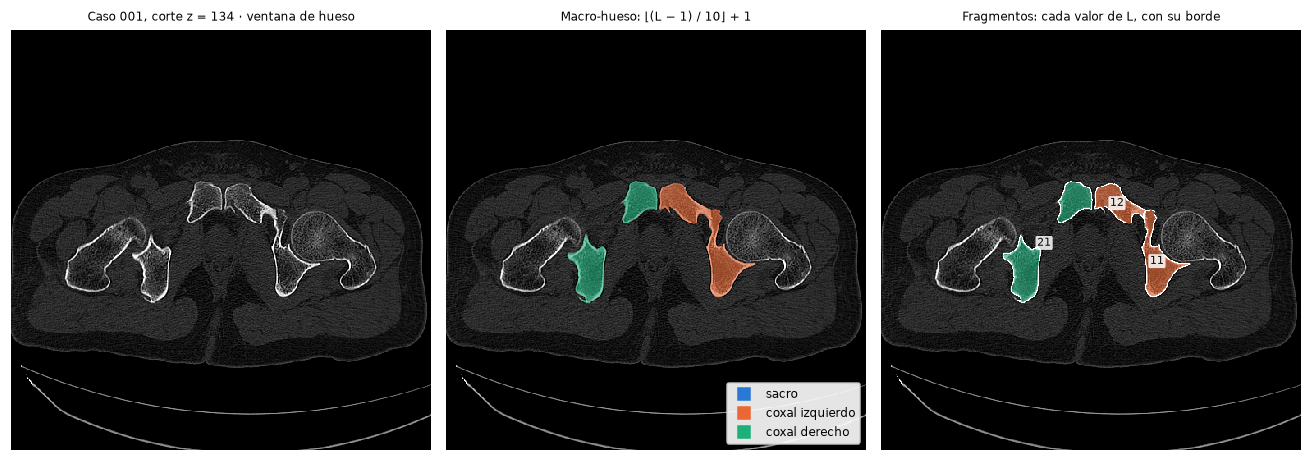

In [ ]:
def mostrar_corte(ax, hu2d, lab2d=None, titulo="", fragmentos=False):
    ax.imshow(np.clip(hu2d, -200, 1300), cmap="gray", interpolation="nearest")
    if lab2d is not None and lab2d.any():
        h = a_hueso(lab2d)
        capa = np.zeros((*lab2d.shape, 4))
        for k, c in COLOR.items():
            capa[h == k] = (*mcolors.to_rgb(c), 0.6)
        if fragmentos:
            borde = (ndimage.grey_dilation(lab2d, size=3) != ndimage.grey_erosion(lab2d, size=3)) & (lab2d > 0)
            capa[borde] = (1, 1, 1, 1)
            for v in np.unique(lab2d[lab2d > 0]):
                cy, cx = ndimage.center_of_mass(lab2d == v)
                ax.text(cx, cy, str(v), fontsize=7, ha="center", va="center", color=TINTA,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
        ax.imshow(capa, interpolation="nearest")
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")


def leyenda_huesos(destino, **kw):
    marcas = [plt.Line2D([], [], marker="s", ls="", ms=8, color=COLOR[k], label=HUESO[k]) for k in COLOR]
    destino.legend(handles=marcas, fontsize=8, **kw)

z = int(np.argmax((lab == 12).sum(axis=(1, 2))))
fig, axs = plt.subplots(1, 3, figsize=(12, 4.4))
mostrar_corte(axs[0], img[z], titulo=f"Caso {caso}, corte z = {z} · ventana de hueso")
mostrar_corte(axs[1], img[z], lab[z], titulo="Macro-hueso: ⌊(L − 1) / 10⌋ + 1")
mostrar_corte(axs[2], img[z], lab[z], titulo="Fragmentos: cada valor de L, con su borde", fragmentos=True)
leyenda_huesos(axs[1], loc="lower right", framealpha=0.9)
fig.tight_layout()
plt.show()

En el corte seleccionado del caso `001` se observa que el sacro tiene la etiqueta `1`, el coxal izquierdo presenta los fragmentos `11` y `12`, y el coxal derecho tiene la etiqueta `21`. En la figura central, los colores permiten distinguir las tres regiones anatómicas; en la última, los bordes y números muestran los fragmentos por separado.

Este ejemplo también permite ver que los fragmentos `11` y `12` del coxal izquierdo están muy próximos entre sí. Por eso es importante conservar las etiquetas individuales durante la segmentación.

Para el caché, guardaremos las imágenes en `int16` y las etiquetas en `uint8`. Como los valores de la máscara están entre `0` y `30`, podemos reducir su uso de memoria sin necesidad de guardar por separado las etiquetas de los macro-huesos y los fragmentos.

## 1.3. Orden de los ejes

Al trabajar con SimpleITK y NumPy, debemos tener en cuenta que los ejes se organizan en órdenes diferentes. SimpleITK devuelve el espaciado como `(x, y, z)`, mientras que el arreglo obtenido con NumPy tiene el orden `(z, y, x)`. Si usamos el espaciado sin ajustarlo, las distancias calculadas pueden ser incorrectas.

In [ ]:
sint = sitk.Image(5, 5, 5, sitk.sitkUInt8)            
sint.SetSpacing((1.0, 2.0, 4.0))                      
arr = sitk.GetArrayFromImage(sint)                    

principal = np.zeros(arr.shape, bool)
principal[1, 2, 2] = True
vecino_en_z = np.zeros(arr.shape, bool)
vecino_en_z[2, 2, 2] = True                          

def distancia_sintetica(espaciado):
    return ndimage.distance_transform_edt(~principal, sampling=espaciado)[vecino_en_z].min()


print(f"GetSpacing() = {sint.GetSpacing()}   → orden (x, y, z)")
print(f"array.shape  = {arr.shape}         → orden (z, y, x)\n")
print(f"Distancia con el espaciado invertido a (z, y, x)   : {distancia_sintetica(sint.GetSpacing()[::-1]):.1f} mm  ← correcta")
print(f"Distancia con el espaciado tal como lo da SimpleITK: {distancia_sintetica(sint.GetSpacing()):.1f} mm  ← error silencioso")

error = (cab.sx - cab.sz).abs() / cab.sz
print(f"\nEn este dataset, el error a lo largo de z llegaría al {error.max():.0%} (caso {error.idxmax()}); mediana {error.median():.0%}")

GetSpacing() = (1.0, 2.0, 4.0)   → orden (x, y, z)
array.shape  = (5, 5, 5)         → orden (z, y, x)

Distancia con el espaciado invertido a (z, y, x)   : 4.0 mm  ← correcta
Distancia con el espaciado tal como lo da SimpleITK: 1.0 mm  ← error silencioso

En este dataset, el error a lo largo de z llegaría al 53% (caso 039); mediana 14%


La prueba muestra que utilizar el orden incorrecto puede cambiar una distancia de 4 mm a 1 mm sin generar un error en el código. En los datos de PENGWIN, la diferencia en el eje z podría llegar al 53 %, con una mediana del 14 %.

Por eso, cuando trabajamos con arreglos de NumPy, utilizamos el espaciado en orden `(z, y, x)`, invirtiendo el valor obtenido con `GetSpacing()`. Después del remuestreo isotrópico a 1,5 mm, los tres ejes tienen el mismo espaciado, pero esta precaución sigue siendo necesaria al trabajar con los volúmenes originales.

## 1.4. Espaciado físico de las tomografías

Los vóxeles no tienen necesariamente el mismo tamaño en todos los pacientes. Por eso, revisamos el espaciado en los ejes x, y y z para conocer las diferencias entre las tomografías y definir una resolución común para el modelo.

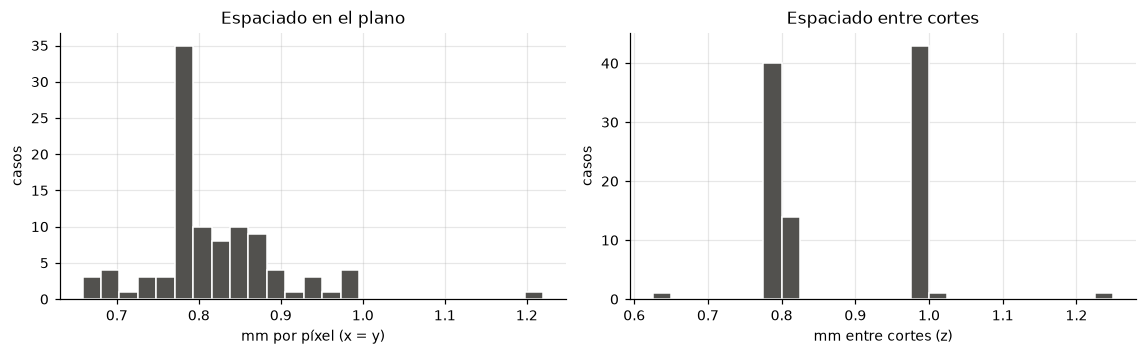

En el plano : 0.658 – 1.220 mm  (factor 1.85×)
Entre cortes: 0.625 – 1.250 mm  (factor 2.00×)
Volúmenes ya isotrópicos: 0 de 100
Cortes por volumen: 193 – 414 (mediana 326)


In [7]:
assert np.allclose(cab.sx, cab.sy), "se esperaban píxeles cuadrados"
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].hist(cab.sx, bins=25, color=NEUTRO, edgecolor="white")
axs[0].set(title="Espaciado en el plano", xlabel="mm por píxel (x = y)", ylabel="casos")
axs[1].hist(cab.sz, bins=25, color=NEUTRO, edgecolor="white")
axs[1].set(title="Espaciado entre cortes", xlabel="mm entre cortes (z)", ylabel="casos")
fig.tight_layout()
plt.show()

print(f"En el plano : {cab.sx.min():.3f} – {cab.sx.max():.3f} mm  (factor {cab.sx.max() / cab.sx.min():.2f}×)")
print(f"Entre cortes: {cab.sz.min():.3f} – {cab.sz.max():.3f} mm  (factor {cab.sz.max() / cab.sz.min():.2f}×)")
print(f"Volúmenes ya isotrópicos: {int(np.isclose(cab.sx, cab.sz, atol=1e-3).sum())} de {len(cab)}")
print(f"Cortes por volumen: {cab.nz.min()} – {cab.nz.max()} (mediana {int(cab.nz.median())})")

Los histogramas muestran que el espaciado varía entre pacientes, tanto dentro de cada corte como entre cortes. Ninguno de los volúmenes tiene el mismo espaciado en los tres ejes, por lo que necesitamos remuestrearlos a una resolución común.

Para elegir la resolución, comparamos cuánto espacio físico cubriría un recorte de 256 × 256 píxeles:

- **1,0 mm:** cubre 256 mm por lado, lo que puede dejar por fuera parte de la pelvis.
- **1,5 mm:** cubre 384 mm por lado y permite conservar la pelvis con margen.
- **2,0 mm:** cubre 512 mm por lado, pero reduce el detalle de los fragmentos pequeños.

Por estas razones, trabajamos con un espaciado de **1,5 mm en los tres ejes**, de modo que las imágenes tengan una escala física común y las distancias puedan calcularse correctamente.

In [8]:
sz, sy, sx = img_sitk.GetSpacing()[::-1]
hueso = lab > 0
ext = {e: (np.ptp(np.nonzero(hueso.any(axis=ejes))[0]) + 1) * s
       for e, ejes, s in (("z", (1, 2), sz), ("y", (0, 2), sy), ("x", (0, 1), sx))}
print(f"Hueso del caso {caso}: {ext['x']:.0f} mm de ancho (x) · {ext['y']:.0f} mm de fondo (y) · {ext['z']:.0f} mm de alto (z)")
print(f"Campo del recorte, 256 px × 1.5 mm = {256 * 1.5:.0f} mm → sobran {256 * 1.5 - max(ext['x'], ext['y']):.0f} mm en el eje más ancho")

Hueso del caso 001: 296 mm de ancho (x) · 162 mm de fondo (y) · 233 mm de alto (z)
Campo del recorte, 256 px × 1.5 mm = 384 mm → sobran 88 mm en el eje más ancho


En el caso 001, el hueso ocupa aproximadamente 296 mm de ancho, 162 mm de fondo y 233 mm de alto. El campo de 384 mm del recorte permite cubrir su ancho con un margen de 88 mm.

Sin embargo, este resultado corresponde a un solo paciente. Más adelante comprobaremos en otros casos si el recorte conserva todos los vóxeles de hueso.

## 1.5. Orientación de los volúmenes

Además del tamaño y el espaciado, las tomografías tienen una matriz de dirección que indica cómo están orientados sus ejes. Revisamos esta información para comprobar si todos los pacientes tienen la misma orientación antes de preparar los datos para el modelo.

In [9]:
identidad = (1, 0, 0, 0, 1, 0, 0, 0, 1)
for d, n in cab.direccion.value_counts().items():
    m = np.array(d, float).reshape(3, 3)
    print(f"{n:>3} casos · dirección {d} · diagonal {tuple(int(v) for v in np.diag(m))} · determinante {np.linalg.det(m):+.0f}")
girados = cab.index[cab.direccion.map(lambda d: d != identidad).to_numpy()]
girado = girados[0]

 66 casos · dirección (1, 0, 0, 0, 1, 0, 0, 0, 1) · diagonal (1, 1, 1) · determinante +1
 34 casos · dirección (-1, 0, 0, 0, -1, 0, 0, 0, 1) · diagonal (-1, -1, 1) · determinante +1


En el dataset encontramos dos orientaciones: 66 casos tienen la matriz identidad y 34 presentan los dos primeros ejes invertidos. Esto corresponde a una rotación de 180° en el plano, no a un reflejo, ya que el determinante sigue siendo +1.

Esta diferencia puede observarse en las imágenes de dos pacientes: aunque representan la misma anatomía, la pelvis aparece girada en uno de ellos. Por eso, es necesario revisar la orientación antes de preparar los datos para el modelo.

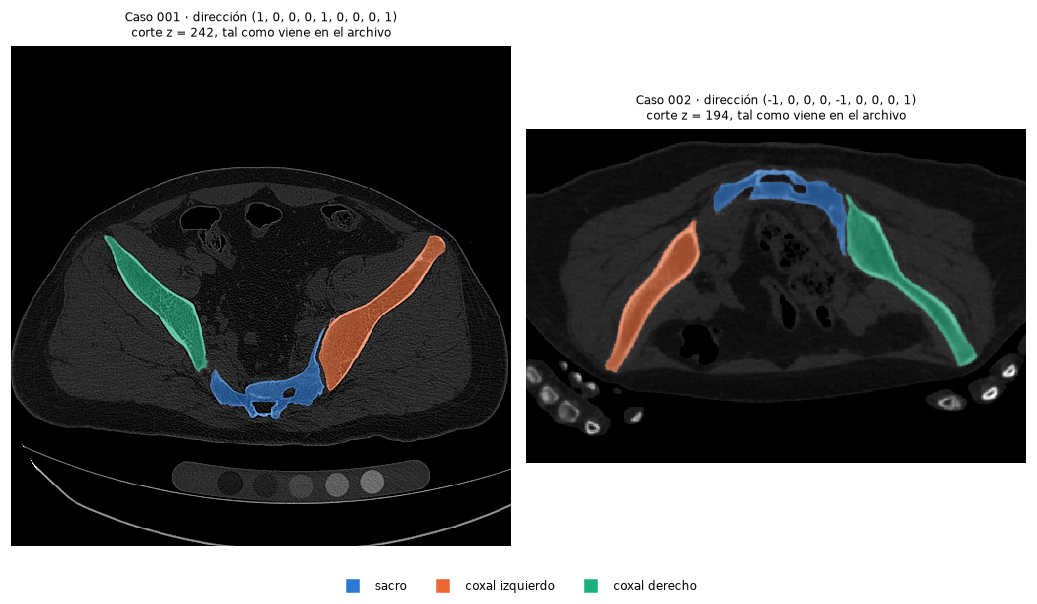

In [ ]:
def z_tres_huesos(lab3d: np.ndarray) -> int:
    presentes = [((lab3d >= 10 * k - 9) & (lab3d <= 10 * k)).any(axis=(1, 2)) for k in (1, 2, 3)]
    return int(np.median(np.nonzero(np.all(presentes, axis=0))[0]))

img_g = sitk.GetArrayFromImage(sitk.ReadImage(str(IMAGES / f"{girado}.mha")))
lab_g = sitk.GetArrayFromImage(sitk.ReadImage(str(LABELS / f"{girado}.mha")))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 5.2))
for ax, (c, im, lb) in zip(axs, [(caso, img, lab), (girado, img_g, lab_g)]):
    zc = z_tres_huesos(lb)
    mostrar_corte(ax, im[zc], lb[zc], titulo=f"Caso {c} · dirección {cab.direccion[c]}\ncorte z = {zc}, tal como viene en el archivo")
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
del img_g, lab_g

En el caso 001, el sacro aparece en la parte inferior de la imagen y el coxal izquierdo a la derecha. En el otro caso, la pelvis está girada 180°. Si no corregimos esta diferencia, el modelo tendría que aprender las mismas estructuras en dos orientaciones distintas, lo que podría dificultar la clasificación entre el coxal izquierdo y el derecho.

Por esta razón, orientamos los volúmenes a la convención LPS mediante `sitk.DICOMOrient` antes del remuestreo. Esta operación ajusta la orientación de los ejes sin interpolar los valores de las imágenes ni modificar las etiquetas de las máscaras.

## 1.6. Distribución del hueso a lo largo de los cortes

Las tomografías incluyen zonas por encima y por debajo de la pelvis donde no hay hueso anotado. Para entender qué parte del volumen contiene información útil, revisamos el área de hueso presente en cada corte del caso `001`.

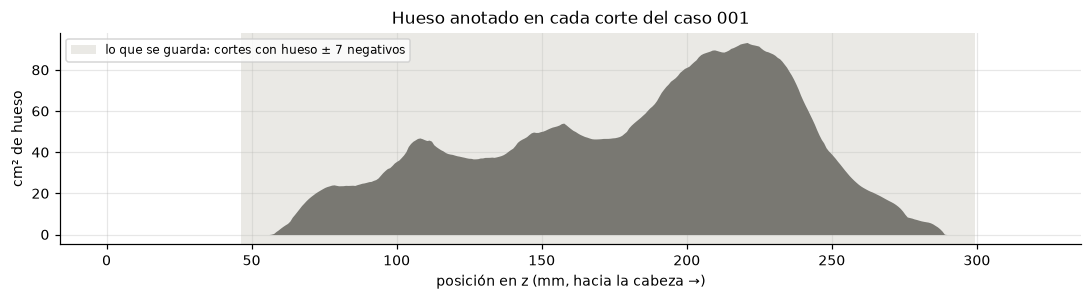

Cortes con hueso: 291 de 401 (73%), de z = 57 a 289 mm


In [ ]:
area = (lab > 0).sum(axis=(1, 2)) * sy * sx / 100      
z_mm = np.arange(len(area)) * sz
con = np.nonzero(area)[0]
margen = 7 * 1.5                                    

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.fill_between(z_mm, area, color=NEUTRO, lw=0)
ax.axvspan(z_mm[con[0]] - margen, z_mm[con[-1]] + margen, color=GRIS, alpha=0.35, lw=0,
           label="lo que se guarda: cortes con hueso ± 7 negativos")
ax.set(title=f"Hueso anotado en cada corte del caso {caso}", xlabel="posición en z (mm, hacia la cabeza →)",
       ylabel="cm² de hueso")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"Cortes con hueso: {con.size} de {len(area)} ({con.size / len(area):.0%}), de z = {z_mm[con[0]]:.0f} a {z_mm[con[-1]]:.0f} mm")

En el caso `001`, encontramos hueso anotado en 291 de los 401 cortes (73 %), entre los 57 y 289 mm de posición en el eje z. Los cortes alejados de este rango no contienen hueso anotado, mientras que los que están cerca de sus extremos pueden servir como ejemplos negativos para que el modelo aprenda dónde termina la región ósea.

Por eso, conservamos los cortes que contienen hueso y siete cortes adicionales a cada lado como negativos. Con el espaciado de 1,5 mm, estos representan aproximadamente 10,5 mm por lado.

## 1.7. Preparación del caché

Como el entrenamiento utiliza muchos cortes de diferentes pacientes, leer y procesar los archivos originales en cada época aumentaría el tiempo de ejecución. Por eso, preparamos un caché que permite acceder a los datos más rápido y evita repetir el preprocesamiento.

Guardaremos las imágenes en formato `.npy` con intensidades HU en `int16` y las etiquetas en `uint8`, manteniendo sus valores originales. También crearemos un índice con información de cada corte y un informe por paciente para registrar la geometría y las verificaciones realizadas. Las ventanas HU se aplicarán durante la carga de los datos, sin necesidad de modificar el caché.